In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import sympy as sp

In [28]:
def F(x, r, N, xc):
    return r*x*(1 - 1/(1 + np.exp(xc - x))
                + x/((1 + np.exp(xc - x))*(N + x)))

def dF_dx(x, r, N, xc, h=1e-6):
    return (F(x+h, r, N, xc) - F(x-h, r, N, xc)) / (2*h)

def plot_stability(param_sets, x_max_map, n_max_map, ncols, x_len, y_len):
    nrows = int(np.ceil(len(param_sets) / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(x_len, y_len))
    axes = axes.flatten()
    
    for ax, (r, xc) in zip(axes, param_sets):
        x_max = 10
        r_max = 350
        x = np.linspace(-3, x_max, 500)
        n = np.linspace(-20, r_max, 500)
        N, X = np.meshgrid(n, x)
    
        G = X - F(X, r, N, xc)
        dF = dF_dx(X, r, N, xc)
        
        stable = (dF > -1) & (dF < 1)
    
        # ax.contourf(
        #     R, X, stable,
        #     levels=[0.5, 1],
        #     colors=['#ccffe5'],
        #     alpha=0.7
        # )
        # 
        # ax.contour(R, X, G, levels=[0], colors='black', linewidths=2)
        # ax.contour(R, X, dF, levels=[-1], colors='blue', linestyles='dashed')
        # ax.contour(R, X, dF, levels=[1], colors='red', linestyles='dashed')
        
        ax.contourf(
            N, X, stable,
            levels=[0.5, 1],
            colors=['#ccffe5'],
            alpha=0.8
        )

        # ===== КРИВЫЕ =====
        c_stationary = ax.contour(
            N, X, G,
            levels=[0],
            colors='black',
            linewidths=2
        )

        c_minus = ax.contour(
            N, X, dF,
            levels=[-1],
            colors='blue',
            linestyles='dashed'
        )

        c_plus = ax.contour(
            N, X, dF,
            levels=[1],
            colors='red',
            linestyles='dashed'
        )

        # ===== ПОДПИСИ НА ЛИНИЯХ =====
        mask = np.abs(G) < 0.01 * x_max
        i, j = np.argwhere(mask)[len(np.argwhere(mask)) // 2]
        
        ax.text(
            N[i, j], X[i, j], 'x*',
            fontsize=8,
            ha='center',
            va='center',
            bbox=dict(facecolor='white', edgecolor='none', pad=0.3)
        )
        ax.clabel(c_minus, fmt={-1: 'F`=-1'}, fontsize=8)
        ax.clabel(c_plus, fmt={1: 'F`=1'}, fontsize=8)

        # ===== ПОДПИСЬ ВНУТРИ ЗЕЛЁНОЙ ОБЛАСТИ =====
        # выбираем точку, где stable == True
        idx = np.argwhere(stable)
        if idx.size > 0:
            i, j = idx[len(idx) // 2]
            ax.text(
                N[i, j], X[i, j], '|F`|<1',
                fontsize=8,
                color='black',
                ha='center',
                va='center'
            )
    
        ax.set_title(f"xc = {xc}, r = {r}")
        ax.set_xlabel("N")
        ax.set_ylabel("x")
        ax.grid(True, linestyle=":", alpha=0.6)
    for i in range(len(param_sets), len(axes)):
        axes[i].axis("off")
    
    # plt.suptitle(
    #     "Неявные стационарные кривые G(x,r)=0 и область |F'(x)| < 1\n"
    #     "Сравнение для различных N и xc",
    #     fontsize=16
    # )
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

D:\Temp\ipykernel_8872\2352867143.py:3: RuntimeWarning: divide by zero encountered in divide
  + x/((1 + np.exp(xc - x))*(N + x)))


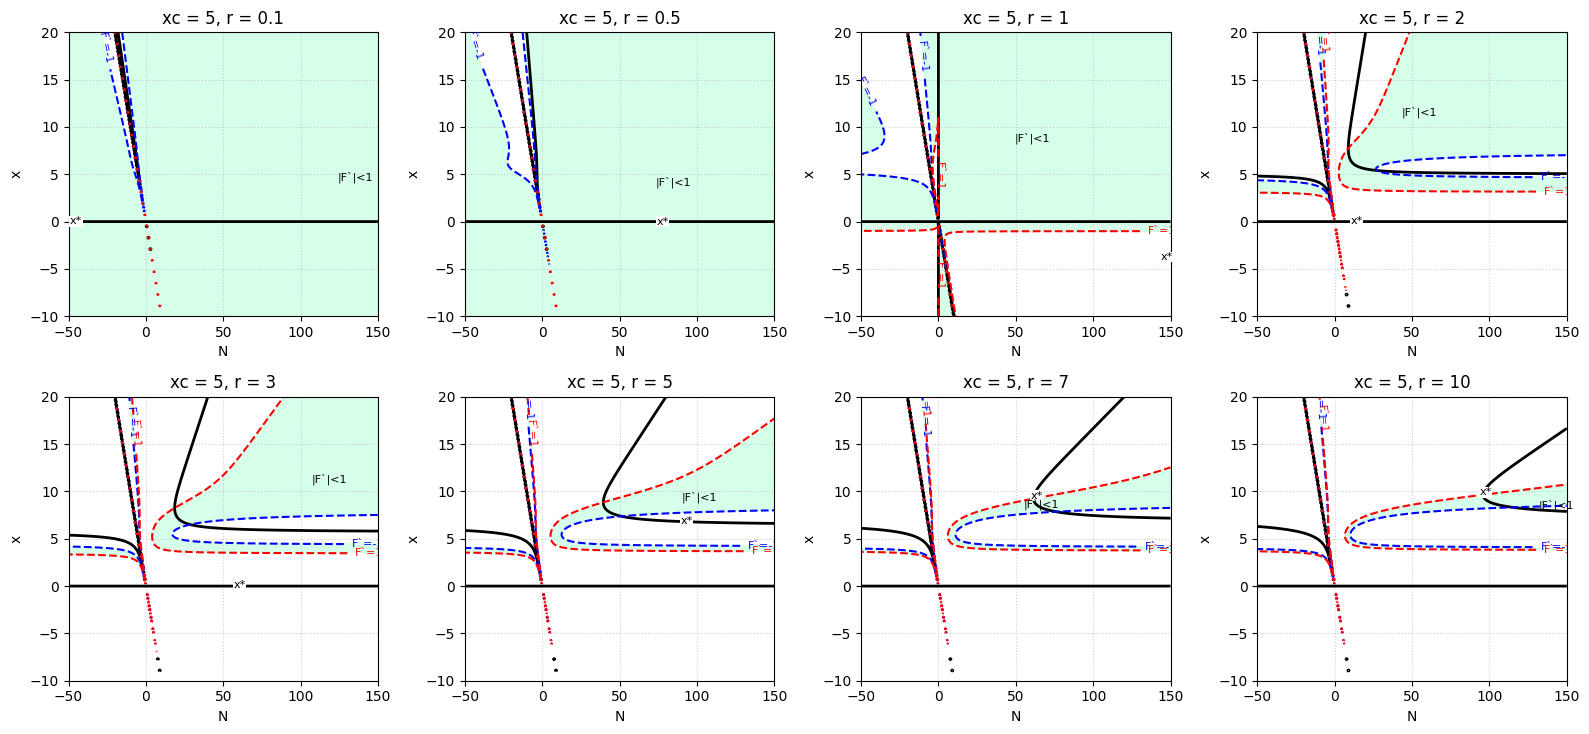

In [20]:
xc_values = [5]
N_values  = [0.1, 0.5, 1, 2, 3, 5, 7, 10]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 44, 5: 20, 25: 20, 0.5: 10, 10: 20, 50: 20, 100: 20, 250: 20, 500: 20, 1000: 20}
r_max_map = {1: 44, 5: 42, 25: 44, 0.5: 4, 10: 44, 50:44, 100: 42, 250: 42, 500: 42, 1000: 80}
ncols = 4

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 8)

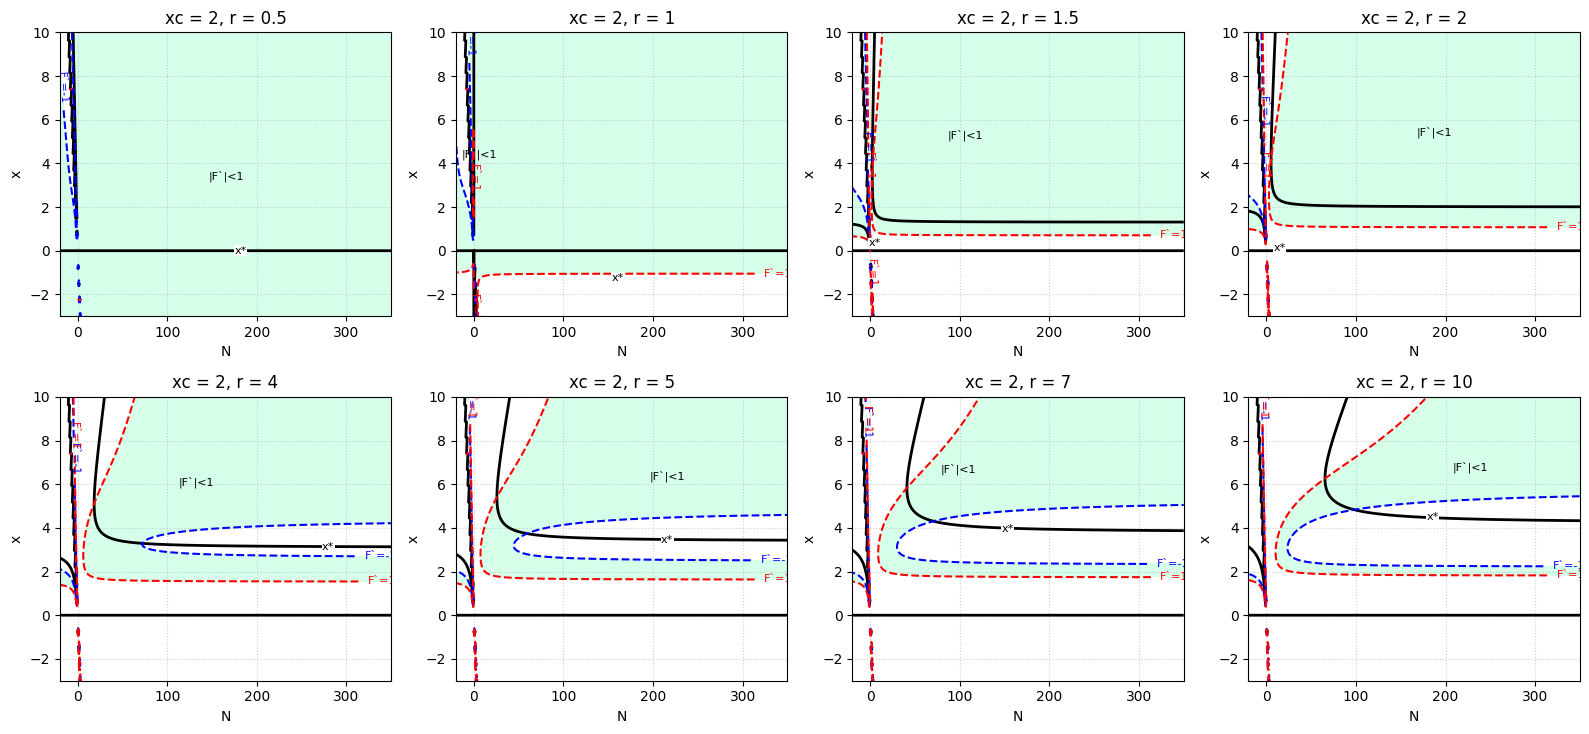

In [29]:
xc_values = [2]
N_values  = [0.5, 1, 1.5, 2, 4, 5, 7, 10]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 44, 5: 20, 25: 20, 0.5: 10, 10: 20, 50: 20, 100: 20, 250: 20, 500: 20, 1000: 20}
r_max_map = {1: 44, 5: 42, 25: 44, 0.5: 4, 10: 44, 50:44, 100: 42, 250: 42, 500: 42, 1000: 80}
ncols = 4

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 8)

D:\Temp\ipykernel_8872\893747863.py:3: RuntimeWarning: divide by zero encountered in divide
  + x/((1 + np.exp(xc - x))*(N + x)))


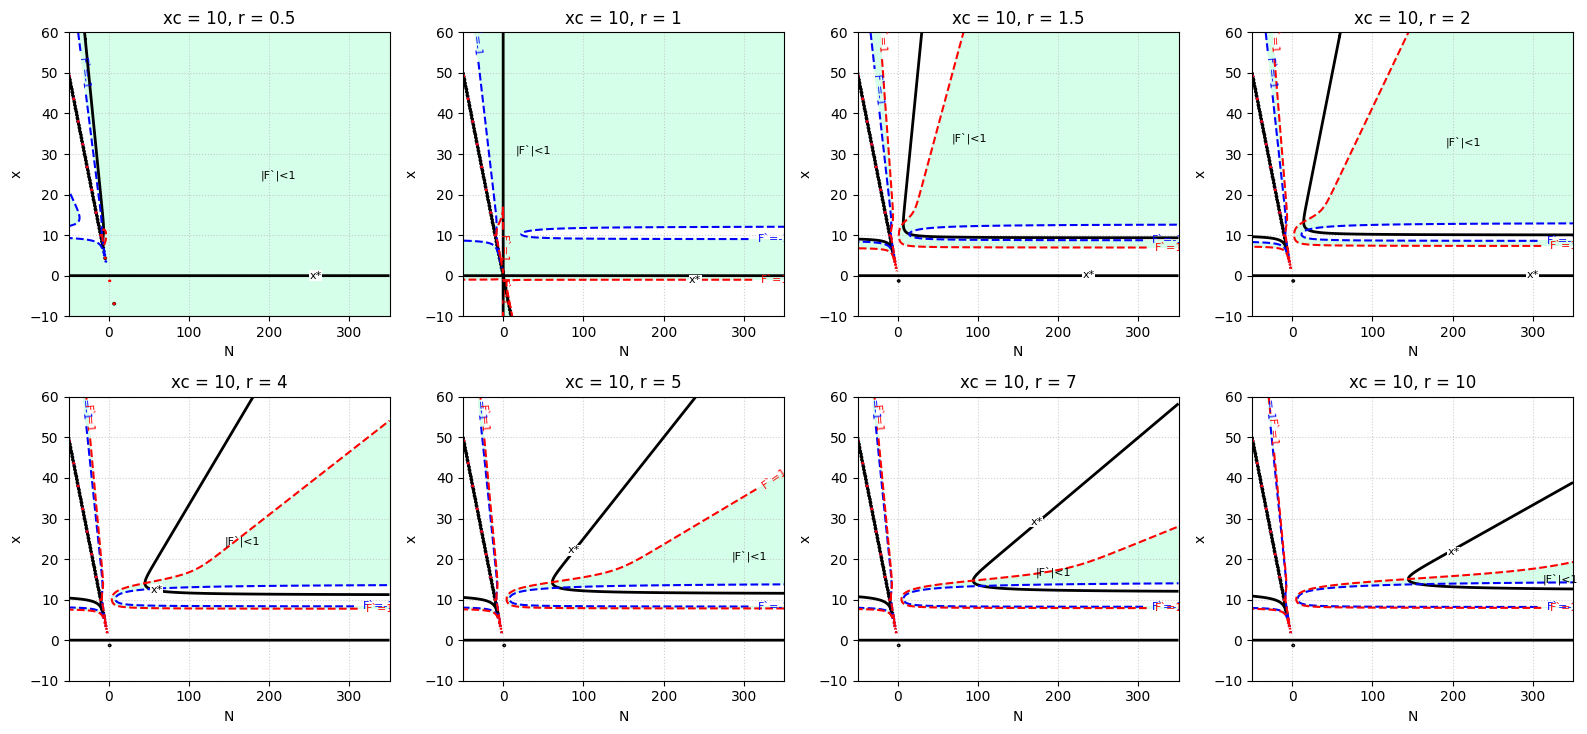

In [25]:
xc_values = [10]
N_values  = [0.5, 1, 1.5, 2, 4, 5, 7, 10]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 44, 5: 20, 25: 20, 0.5: 10, 10: 20, 50: 20, 100: 20, 250: 20, 500: 20, 1000: 20}
r_max_map = {1: 44, 5: 42, 25: 44, 0.5: 4, 10: 44, 50:44, 100: 42, 250: 42, 500: 42, 1000: 80}
ncols = 4

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 8)

D:\Temp\ipykernel_8872\893747863.py:3: RuntimeWarning: divide by zero encountered in divide
  + x/((1 + np.exp(xc - x))*(N + x)))


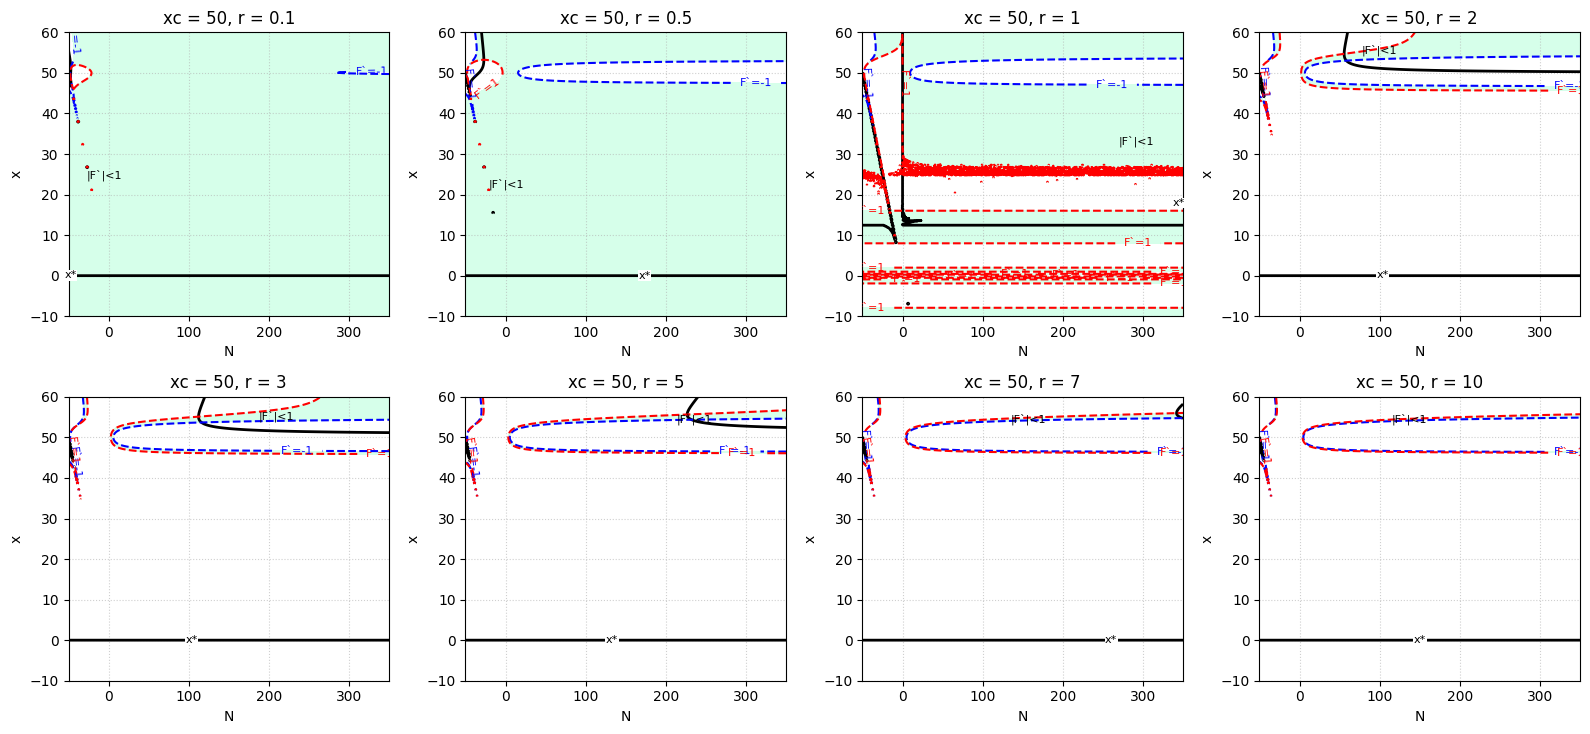

In [23]:
xc_values = [50]
N_values  = [0.1, 0.5, 1, 2, 3, 5, 7, 10]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 44, 5: 20, 25: 20, 0.5: 10, 10: 20, 50: 20, 100: 20, 250: 20, 500: 20, 1000: 20}
r_max_map = {1: 44, 5: 42, 25: 44, 0.5: 4, 10: 44, 50:44, 100: 42, 250: 42, 500: 42, 1000: 80}
ncols = 4

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 8)